In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares


# ============================================================
# 1. Load JUN18 steady-state data
# ============================================================

file_path = "E:/pt/dataset/JUN18.xlsx"

raw = pd.read_excel(
    file_path,
    sheet_name="Steady State & SAOS",
    header=None
)


# SS1: first steady-state experiment
ss1 = pd.DataFrame({
    "shear_rate": pd.to_numeric(raw.iloc[2:18, 0], errors="coerce"),
    "stress": pd.to_numeric(raw.iloc[2:18, 1], errors="coerce")
}).dropna()


# SS2: second steady-state experiment
ss2 = pd.DataFrame({
    "shear_rate": pd.to_numeric(raw.iloc[2:18, 4], errors="coerce"),
    "stress": pd.to_numeric(raw.iloc[2:18, 5], errors="coerce")
}).dropna()


print("SS1")
print(ss1)

print("\nSS2")
print(ss2)

SS1
    shear_rate    stress
2         0.10  0.002059
3         0.20  0.004010
4         0.35  0.007133
5         0.70  0.012580
6         1.00  0.015760
7         2.00  0.023760
8         3.50  0.033711
9         7.00  0.051800
10       10.00  0.065400
11       20.00  0.108970
12       35.00  0.168900
13       70.00  0.298000
14      100.00  0.403668
15      200.00  0.720695
16      350.00  1.185800
17      700.00  2.232500

SS2
    shear_rate   stress
2         0.10  0.00330
3         0.20  0.00575
4         0.35  0.01100
5         0.70  0.01848
6         1.00  0.02326
7         2.00  0.03395
8         3.50  0.04629
9         7.00  0.06833
10       10.00  0.08490
11       20.00  0.13600
12       35.00  0.20320
13       70.00  0.34850
14      100.00  0.46330
15      200.00  0.84800
16      350.00  1.41000
17      700.00  2.71000


In [2]:
# ============================================================
# 2. Fixed parameters for human blood
# ============================================================

d = 0.5
m = 1.5


# ============================================================
# 3. Steady-state t-ESSTV model
# ============================================================

def tesstv_steady(
    shear_rate,
    mu_zero,
    mu_inf,
    tau_cross,
    tau_break,
    tau_build,
    mu_rouleaux,
    yield_stress
):
    """
    Calculate steady-state t-ESSTV stress.

    Input:
        shear_rate

    Fitted parameters:
        mu_zero
        mu_inf
        tau_cross
        tau_break
        tau_build
        mu_rouleaux
        yield_stress

    Output:
        predicted total stress
    """

    shear_rate = np.asarray(
        shear_rate,
        dtype=float
    )


    # --------------------------------------------------------
    # Plasma + individual RBC viscosity
    # --------------------------------------------------------

    viscosity = (
        mu_inf
        + (mu_zero - mu_inf)
        / (
            1
            + tau_cross * np.abs(shear_rate)
        )
    )


    # --------------------------------------------------------
    # Rouleaux steady-state structure lambda
    # --------------------------------------------------------

    build_term = (
        np.abs(
            tau_build * shear_rate
        ) ** d
        + 1
    )

    break_term = (
        tau_break
        * np.abs(shear_rate)
    )

    lam = (
        build_term
        / (
            break_term
            + build_term
        )
    )


    # --------------------------------------------------------
    # Stress components
    # --------------------------------------------------------

    cell_stress = (
        viscosity
        * shear_rate
    )

    rouleaux_viscous_stress = (
        mu_rouleaux
        * lam ** m
        * shear_rate
    )

    rouleaux_yield_stress = (
        yield_stress
        * lam
        * np.sign(shear_rate)
    )


    total_stress = (
        cell_stress
        + rouleaux_viscous_stress
        + rouleaux_yield_stress
    )


    return total_stress

In [3]:
# ============================================================
# 4. Residual used by the optimizer
# ============================================================

def steady_residuals(
    params,
    shear_rate,
    measured_stress
):

    predicted_stress = tesstv_steady(
        shear_rate,
        *params
    )


    # Relative residual:
    # prevents high-stress points from dominating everything
    scale = np.maximum(
        np.abs(measured_stress),
        1e-4
    )

    residual = (
        predicted_stress
        - measured_stress
    ) / scale


    return residual

In [4]:
# ============================================================
# 5. Fit one steady-state dataset
# ============================================================

def fit_steady_data(data):

    shear_rate = data[
        "shear_rate"
    ].to_numpy(dtype=float)

    measured_stress = data[
        "stress"
    ].to_numpy(dtype=float)


    # Published Donor 5 values:
    # only used as initial guesses
    initial_guess = [
        0.0138,   # mu_zero
        0.0054,   # mu_inf
        0.029,    # tau_cross
        1.582,    # tau_break
        0.192,    # tau_build
        0.099,    # mu_rouleaux
        0.0039    # yield_stress
    ]


    lower_bounds = [
        1e-4,
        1e-4,
        1e-5,
        1e-4,
        1e-8,
        1e-4,
        0.0
    ]


    upper_bounds = [
        0.1,
        0.1,
        10.0,
        20.0,
        20.0,
        1.0,
        0.1
    ]


    result = least_squares(
        steady_residuals,

        x0=initial_guess,

        bounds=(
            lower_bounds,
            upper_bounds
        ),

        args=(
            shear_rate,
            measured_stress
        ),

        max_nfev=30000
    )


    fitted_params = result.x


    predicted_stress = tesstv_steady(
        shear_rate,
        *fitted_params
    )


    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    rmse = np.sqrt(
        np.mean(
            (
                measured_stress
                - predicted_stress
            ) ** 2
        )
    )


    # --------------------------------------------------------
    # R²
    # --------------------------------------------------------

    ss_res = np.sum(
        (
            measured_stress
            - predicted_stress
        ) ** 2
    )

    ss_tot = np.sum(
        (
            measured_stress
            - np.mean(measured_stress)
        ) ** 2
    )

    r2 = (
        1
        - ss_res / ss_tot
    )


    return {
        "params": fitted_params,
        "shear_rate": shear_rate,
        "measured": measured_stress,
        "predicted": predicted_stress,
        "rmse": rmse,
        "r2": r2,
        "success": result.success
    }

In [5]:
# ============================================================
# 6. Fit SS1 and SS2
# ============================================================

fit_ss1 = fit_steady_data(ss1)
fit_ss2 = fit_steady_data(ss2)

In [6]:
# ============================================================
# 7. Print fitted parameters
# ============================================================

parameter_names = [
    "mu_zero",
    "mu_inf",
    "tau_cross",
    "tau_break",
    "tau_build",
    "mu_rouleaux",
    "yield_stress"
]


def print_fit(name, fit):

    print(f"\n{name}")
    print("=" * 40)

    for parameter_name, value in zip(
        parameter_names,
        fit["params"]
    ):

        print(
            f"{parameter_name:15s} = {value:.6g}"
        )


    print(
        f"\nRMSE = {fit['rmse']:.6f} Pa"
    )

    print(
        f"R²   = {fit['r2']:.6f}"
    )


print_fit(
    "JUN18 SS1",
    fit_ss1
)

print_fit(
    "JUN18 SS2",
    fit_ss2
)


JUN18 SS1
mu_zero         = 0.0214696
mu_inf          = 0.00294549
tau_cross       = 0.65347
tau_break       = 0.00362184
tau_build       = 1e-08
mu_rouleaux     = 0.00126008
yield_stress    = 4.90627e-51

RMSE = 0.003244 Pa
R²   = 0.999969

JUN18 SS2
mu_zero         = 0.0338508
mu_inf          = 0.00371574
tau_cross       = 0.704221
tau_break       = 0.00682749
tau_build       = 1e-08
mu_rouleaux     = 0.0011766
yield_stress    = 7.75586e-47

RMSE = 0.002339 Pa
R²   = 0.999989


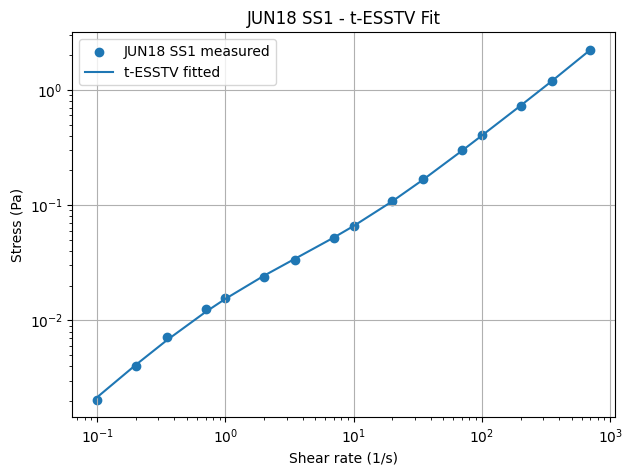

In [7]:
# ============================================================
# 8. Plot SS1 fit
# ============================================================

order = np.argsort(
    fit_ss1["shear_rate"]
)


plt.figure(figsize=(7, 5))

plt.scatter(
    fit_ss1["shear_rate"],
    fit_ss1["measured"],
    label="JUN18 SS1 measured"
)

plt.plot(
    fit_ss1["shear_rate"][order],
    fit_ss1["predicted"][order],
    label="t-ESSTV fitted"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Stress (Pa)")

plt.title(
    "JUN18 SS1 - t-ESSTV Fit"
)

plt.legend()
plt.grid(True)

plt.show()

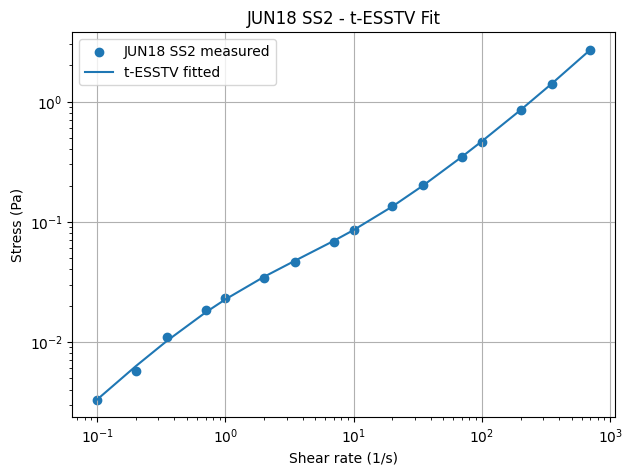

In [8]:
# ============================================================
# 9. Plot SS2 fit
# ============================================================

order = np.argsort(
    fit_ss2["shear_rate"]
)


plt.figure(figsize=(7, 5))

plt.scatter(
    fit_ss2["shear_rate"],
    fit_ss2["measured"],
    label="JUN18 SS2 measured"
)

plt.plot(
    fit_ss2["shear_rate"][order],
    fit_ss2["predicted"][order],
    label="t-ESSTV fitted"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Stress (Pa)")

plt.title(
    "JUN18 SS2 - t-ESSTV Fit"
)

plt.legend()
plt.grid(True)

plt.show()

### Step Up/Down

Using SS1
    shear_rate    stress
2         0.10  0.002059
3         0.20  0.004010
4         0.35  0.007133
5         0.70  0.012580
6         1.00  0.015760
7         2.00  0.023760
8         3.50  0.033711
9         7.00  0.051800
10       10.00  0.065400
11       20.00  0.108970
12       35.00  0.168900
13       70.00  0.298000
14      100.00  0.403668
15      200.00  0.720695
16      350.00  1.185800
17      700.00  2.232500


SS1 fitted steady-state parameters
mu_zero        = 0.02146961
mu_inf         = 0.00294549
tau_cross      = 0.65347042
tau_break      = 0.00362184
tau_build      = 0.00000001
mu_rouleaux    = 0.00126008
yield_stress   = 0.00000000

SS RMSE = 0.003244 Pa
SS R²   = 0.999969

Transient points: 4186

Fitted transient parameters
tau_structure = 0.32098846 s
G_rouleaux    = 1.47850455 Pa
G_cell        = 0.18806262 Pa

Transient RMSE = 0.004844 Pa
Transient R²   = -1.562745


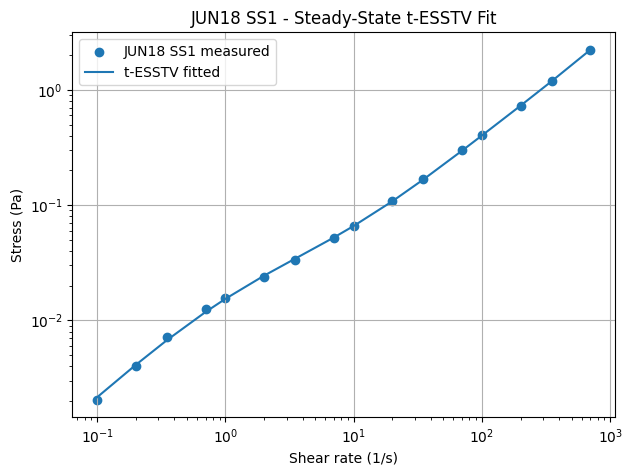

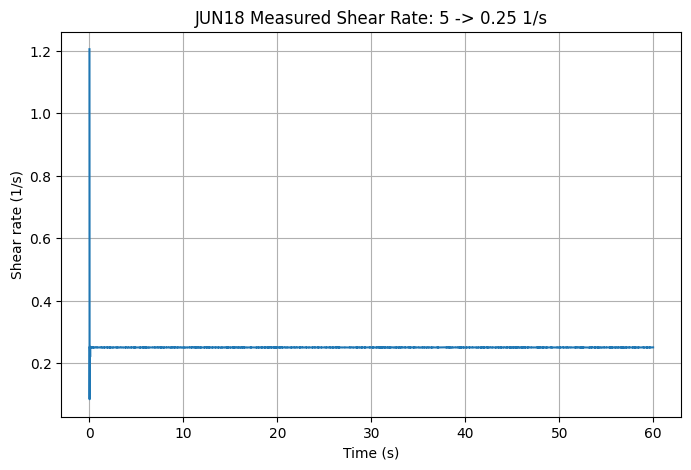

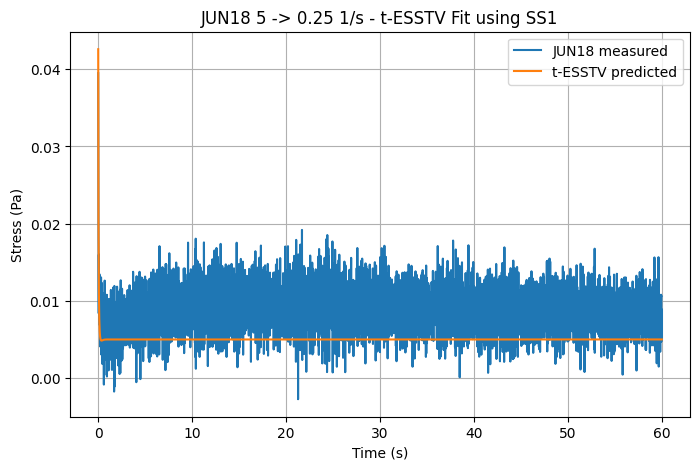

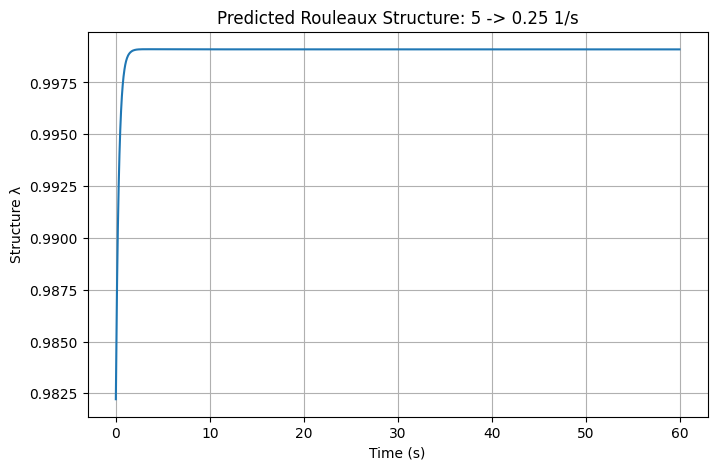

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import least_squares
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d


# ============================================================
# USER SETTINGS
# ============================================================

FILE_PATH = "/mnt/c/Users/sylvi/Desktop/JUN18.xlsx"

# Choose which JUN18 steady-state run to use
SS_RUN = "SS1"       # change to "SS2" if needed

# For now, fit this real transient experiment
STEP_NAME = "5_to_0.25"


# ============================================================
# FIXED PARAMETERS FOR HUMAN BLOOD
# ============================================================

d = 0.5
m = 1.5
gamma0_rouleaux = 1.0


# ============================================================
# 1. LOAD JUN18 STEADY-STATE DATA
# ============================================================

raw_ss = pd.read_excel(
    FILE_PATH,
    sheet_name="Steady State & SAOS",
    header=None
)


if SS_RUN == "SS1":

    ss_data = pd.DataFrame({
        "shear_rate":
            pd.to_numeric(
                raw_ss.iloc[2:18, 0],
                errors="coerce"
            ),

        "stress":
            pd.to_numeric(
                raw_ss.iloc[2:18, 1],
                errors="coerce"
            )
    }).dropna()


elif SS_RUN == "SS2":

    ss_data = pd.DataFrame({
        "shear_rate":
            pd.to_numeric(
                raw_ss.iloc[2:18, 4],
                errors="coerce"
            ),

        "stress":
            pd.to_numeric(
                raw_ss.iloc[2:18, 5],
                errors="coerce"
            )
    }).dropna()


else:

    raise ValueError(
        'SS_RUN must be "SS1" or "SS2"'
    )


ss_shear = ss_data[
    "shear_rate"
].to_numpy(dtype=float)

ss_stress = ss_data[
    "stress"
].to_numpy(dtype=float)


print(f"Using {SS_RUN}")
print(ss_data)


# ============================================================
# 2. STEADY-STATE t-ESSTV MODEL
# ============================================================

def steady_model(
    shear_rate,
    mu_zero,
    mu_inf,
    tau_cross,
    tau_break,
    tau_build,
    mu_rouleaux,
    yield_stress
):

    """
    Steady-state t-ESSTV total stress.
    """

    shear_rate = np.asarray(
        shear_rate,
        dtype=float
    )


    # Plasma + individual RBC viscosity
    viscosity = (
        mu_inf
        + (mu_zero - mu_inf)
        / (
            1
            + tau_cross
            * np.abs(shear_rate)
        )
    )


    # Steady-state rouleaux structure
    build_term = (
        np.abs(
            tau_build * shear_rate
        ) ** d
        + 1
    )

    break_term = (
        tau_break
        * np.abs(shear_rate)
    )

    lam = (
        build_term
        / (
            build_term
            + break_term
        )
    )


    # Plasma / RBC stress
    cell_stress = (
        viscosity
        * shear_rate
    )


    # Rouleaux viscous stress
    rouleaux_viscous_stress = (
        mu_rouleaux
        * lam ** m
        * shear_rate
    )


    # Rouleaux yield stress
    rouleaux_yield_stress = (
        yield_stress
        * lam
        * np.sign(shear_rate)
    )


    total_stress = (
        cell_stress
        + rouleaux_viscous_stress
        + rouleaux_yield_stress
    )


    return total_stress


# ============================================================
# 3. FIT STEADY-STATE PARAMETERS
# ============================================================

def steady_residuals(
    params
):

    predicted = steady_model(
        ss_shear,
        *params
    )


    # Relative error
    scale = np.maximum(
        np.abs(ss_stress),
        1e-4
    )


    return (
        predicted
        - ss_stress
    ) / scale


# Donor 5 values used ONLY as starting guesses
steady_initial_guess = [
    0.0138,   # mu_zero
    0.0054,   # mu_inf
    0.029,    # tau_cross
    1.582,    # tau_break
    0.192,    # tau_build
    0.099,    # mu_rouleaux
    0.0039    # yield_stress
]


steady_lower_bounds = [
    1e-4,
    1e-4,
    1e-5,
    1e-4,
    1e-8,
    1e-4,
    0.0
]


steady_upper_bounds = [
    0.1,
    0.1,
    10.0,
    20.0,
    20.0,
    1.0,
    0.1
]


steady_fit = least_squares(

    steady_residuals,

    x0=steady_initial_guess,

    bounds=(
        steady_lower_bounds,
        steady_upper_bounds
    ),

    max_nfev=30000
)


(
    mu_zero,
    mu_inf,
    tau_cross,
    tau_break,
    tau_build,
    mu_rouleaux,
    yield_stress
) = steady_fit.x


ss_predicted = steady_model(
    ss_shear,
    *steady_fit.x
)


# ============================================================
# 4. STEADY-STATE FIT METRICS
# ============================================================

ss_rmse = np.sqrt(
    np.mean(
        (
            ss_stress
            - ss_predicted
        ) ** 2
    )
)


ss_res = np.sum(
    (
        ss_stress
        - ss_predicted
    ) ** 2
)


ss_tot = np.sum(
    (
        ss_stress
        - np.mean(ss_stress)
    ) ** 2
)


ss_r2 = (
    1
    - ss_res / ss_tot
)


print("\n")
print(
    f"{SS_RUN} fitted steady-state parameters"
)
print("=" * 45)

print(f"mu_zero        = {mu_zero:.8f}")
print(f"mu_inf         = {mu_inf:.8f}")
print(f"tau_cross      = {tau_cross:.8f}")
print(f"tau_break      = {tau_break:.8f}")
print(f"tau_build      = {tau_build:.8f}")
print(f"mu_rouleaux    = {mu_rouleaux:.8f}")
print(f"yield_stress   = {yield_stress:.8f}")

print()
print(f"SS RMSE = {ss_rmse:.6f} Pa")
print(f"SS R²   = {ss_r2:.6f}")


# ============================================================
# 5. LOAD REAL JUN18 STEP-DOWN DATA
#
# JUN18 Excel:
# columns 15-18 = 5 -> 0.25 1/s
# time | stress | strain | shear rate
# ============================================================

raw_step = pd.read_excel(
    FILE_PATH,
    sheet_name="Step Up Step Down",
    header=None
)


if STEP_NAME == "5_to_0.25":

    initial_shear = 5.0

    step_data = pd.DataFrame({

        "time":
            pd.to_numeric(
                raw_step.iloc[3:, 15],
                errors="coerce"
            ),

        "stress":
            pd.to_numeric(
                raw_step.iloc[3:, 16],
                errors="coerce"
            ),

        "shear_rate":
            pd.to_numeric(
                raw_step.iloc[3:, 18],
                errors="coerce"
            )

    }).dropna()


else:

    raise ValueError(
        "Only 5_to_0.25 is configured in this version."
    )


# Make experimental time start at zero
step_data["time"] = (
    step_data["time"]
    - step_data["time"].iloc[0]
)


time_data = step_data[
    "time"
].to_numpy(dtype=float)

stress_data = step_data[
    "stress"
].to_numpy(dtype=float)

shear_data = step_data[
    "shear_rate"
].to_numpy(dtype=float)


print()
print(
    f"Transient points: {len(step_data)}"
)


# ============================================================
# 6. REAL MEASURED SHEAR-RATE FUNCTION
#
# The rheometer does not produce a mathematically perfect step.
# Therefore use the measured shear-rate history.
# ============================================================

shear_function = interp1d(

    time_data,
    shear_data,

    kind="linear",

    bounds_error=False,

    # Before the first recorded point,
    # assume the sample was at 5 1/s.
    fill_value=(
        initial_shear,
        shear_data[-1]
    )
)


# ============================================================
# 7. HELPER FUNCTIONS
# ============================================================

def cross_viscosity(
    shear_rate
):

    """
    Steady plasma/RBC viscosity.
    """

    return (
        mu_inf
        + (mu_zero - mu_inf)
        / (
            1
            + tau_cross
            * abs(shear_rate)
        )
    )


def steady_structure(
    shear_rate
):

    """
    Steady-state rouleaux structure lambda.
    """

    build_term = (
        abs(
            tau_build
            * shear_rate
        ) ** d
        + 1
    )

    break_term = (
        tau_break
        * abs(shear_rate)
    )


    return (
        build_term
        / (
            build_term
            + break_term
        )
    )


def transient_viscosity(
    normal_stress,
    G_cell
):

    """
    Plasma/RBC transient viscosity
    from the White-Metzner auxiliary equation.
    """

    normal_stress = max(
        normal_stress,
        0.0
    )


    root_term = np.sqrt(
        G_cell
        * normal_stress
        / 2
    )


    b = (
        tau_cross
        * root_term
        - mu_zero
    )


    c = (
        -mu_inf
        * tau_cross
        * root_term
    )


    discriminant = (
        b ** 2
        - 4 * c
    )


    discriminant = max(
        discriminant,
        1e-18
    )


    viscosity = (
        -b
        + np.sqrt(discriminant)
    ) / 2


    return max(
        viscosity,
        1e-8
    )


# ============================================================
# 8. INITIAL STATE
#
# Important:
# the first recorded shear-rate point is NOT 5 1/s.
#
# The step has already begun by the time the first recorded
# point appears, so initialise the model from 5 1/s,
# based on the experiment itself.
# ============================================================

def initial_state(
    initial_shear,
    G_cell
):

    lam = steady_structure(
        initial_shear
    )


    elastic_strain = (
        gamma0_rouleaux
        * lam
        * np.sign(initial_shear)
    )


    viscosity = cross_viscosity(
        initial_shear
    )


    cell_shear_stress = (
        viscosity
        * initial_shear
    )


    cell_normal_stress = (
        2
        * viscosity ** 2
        * initial_shear ** 2
        / G_cell
    )


    rouleaux_stress = (
        mu_rouleaux
        * lam ** m
        * initial_shear

        + yield_stress
        * lam
        * np.sign(initial_shear)
    )


    return [
        lam,
        elastic_strain,
        cell_shear_stress,
        cell_normal_stress,
        rouleaux_stress
    ]


# ============================================================
# 9. NON-TENSORIAL TRANSIENT t-ESSTV ODE
# ============================================================

def transient_equations(
    time,
    state,
    tau_structure,
    G_rouleaux,
    G_cell
):

    (
        lam,
        elastic_strain,
        cell_shear_stress,
        cell_normal_stress,
        rouleaux_stress
    ) = state


    # Real experimental shear rate at this time
    shear_rate = float(
        shear_function(time)
    )


    # Keep lambda numerically safe
    lam_safe = np.clip(
        lam,
        1e-6,
        1.0
    )


    # Maximum elastic strain
    max_elastic_strain = (
        gamma0_rouleaux
        * lam_safe
    )


    max_elastic_strain = max(
        max_elastic_strain,
        1e-6
    )


    # --------------------------------------------------------
    # Plastic shear rate
    # --------------------------------------------------------

    denominator = (
        2
        - elastic_strain
        / max_elastic_strain
    )


    if abs(denominator) < 1e-6:

        denominator = (
            1e-6
            if denominator >= 0
            else -1e-6
        )


    plastic_shear_rate = (
        shear_rate
        / denominator
    )


    # --------------------------------------------------------
    # Rouleaux structure evolution
    # --------------------------------------------------------

    breakdown = (
        tau_break
        * abs(plastic_shear_rate)
        * lam_safe
    )


    buildup = (
        (1 - lam_safe)
        * (
            abs(
                tau_build
                * plastic_shear_rate
            ) ** d
            + 1
        )
    )


    d_lambda = (
        buildup
        - breakdown
    ) / tau_structure


    # --------------------------------------------------------
    # Elastic strain evolution
    # --------------------------------------------------------

    d_max_elastic_strain = (
        gamma0_rouleaux
        * d_lambda
    )


    d_elastic_strain = (

        plastic_shear_rate

        - (
            elastic_strain
            / max_elastic_strain
        )
        * abs(plastic_shear_rate)

    )


    if d_max_elastic_strain < 0:

        d_elastic_strain += (
            elastic_strain
            / max_elastic_strain
        ) * d_max_elastic_strain


    # --------------------------------------------------------
    # Plasma / individual RBC contribution
    # --------------------------------------------------------

    viscosity = transient_viscosity(
        cell_normal_stress,
        G_cell
    )


    d_cell_shear_stress = (
        G_cell
        * (
            shear_rate
            - cell_shear_stress
            / viscosity
        )
    )


    d_cell_normal_stress = (

        2
        * shear_rate
        * cell_shear_stress

        - G_cell
        * cell_normal_stress
        / viscosity

    )


    # --------------------------------------------------------
    # Rouleaux EVP stress contribution
    # --------------------------------------------------------

    structure_viscosity = (
        lam_safe ** m
        * mu_rouleaux
    )


    structure_viscosity = max(
        structure_viscosity,
        1e-8
    )


    yield_part = (
        yield_stress
        / gamma0_rouleaux
        * elastic_strain
    )


    stress_difference = (
        rouleaux_stress
        - yield_part
    )


    if abs(rouleaux_stress) > 1e-10:

        stress_direction = np.sign(
            rouleaux_stress
        )

    else:

        stress_direction = np.sign(
            shear_rate
        )


    plastic_flow = (

        abs(stress_difference)
        / structure_viscosity

        * stress_direction

    )


    d_rouleaux_stress = (

        lam_safe
        * G_rouleaux

        * (
            shear_rate
            - plastic_flow
        )

    )


    return [
        d_lambda,
        d_elastic_strain,
        d_cell_shear_stress,
        d_cell_normal_stress,
        d_rouleaux_stress
    ]


# ============================================================
# 10. RUN TRANSIENT MODEL
# ============================================================

def run_transient(
    transient_params,
    output_times
):

    tau_structure = transient_params[0]
    G_rouleaux = transient_params[1]
    G_cell = transient_params[2]


    start_state = initial_state(
        initial_shear,
        G_cell
    )


    solution = solve_ivp(

        fun=lambda t, y:
            transient_equations(
                t,
                y,
                tau_structure,
                G_rouleaux,
                G_cell
            ),

        t_span=(
            time_data[0],
            time_data[-1]
        ),

        y0=start_state,

        t_eval=output_times,

        method="BDF",

        rtol=1e-5,
        atol=1e-7
    )


    if not solution.success:

        return None


    cell_stress = (
        solution.y[2]
    )


    rouleaux_stress = (
        solution.y[4]
    )


    total_stress = (
        cell_stress
        + rouleaux_stress
    )


    return {
        "solution": solution,
        "total_stress": total_stress
    }


# ============================================================
# 11. FIT TRANSIENT PARAMETERS
#
# Fit:
#     tau_structure = tau_lambda
#     G_rouleaux     = G_R
#     G_cell         = G_C
#
# Steady parameters above come from JUN18 SS1 / SS2.
# ============================================================


# Use fewer points while fitting to make optimisation faster.
# Keep dense data near the start because the transient occurs there.

early_points = np.arange(
    0,
    min(200, len(time_data))
)

later_points = np.arange(
    200,
    len(time_data),
    20
)

fit_indices = np.unique(
    np.concatenate([
        early_points,
        later_points,
        [len(time_data) - 1]
    ])
)


fit_times = (
    time_data[fit_indices]
)

fit_stress = (
    stress_data[fit_indices]
)


# Normalise transient residual by maximum measured stress,
# similar to the fitting logic used in the paper.
stress_scale = max(
    np.max(
        np.abs(fit_stress)
    ),
    1e-4
)


def transient_residuals(
    params
):

    result = run_transient(
        params,
        fit_times
    )


    if result is None:

        return np.full(
            len(fit_times),
            1e6
        )


    predicted = result[
        "total_stress"
    ]


    if np.any(
        ~np.isfinite(predicted)
    ):

        return np.full(
            len(fit_times),
            1e6
        )


    return (
        predicted
        - fit_stress
    ) / stress_scale


# Published values are only INITIAL GUESSES here
transient_initial_guess = [
    1.4582,   # tau_structure
    0.2646,   # G_rouleaux
    0.5138    # G_cell
]


transient_lower_bounds = [
    0.01,
    0.001,
    0.01
]


transient_upper_bounds = [
    20.0,
    5.0,
    5.0
]


transient_fit = least_squares(

    transient_residuals,

    x0=transient_initial_guess,

    bounds=(
        transient_lower_bounds,
        transient_upper_bounds
    ),

    # Larger finite-difference step helps because
    # the ODE solution itself has numerical tolerance.
    diff_step=0.05,

    max_nfev=200
)


tau_structure_fit = (
    transient_fit.x[0]
)

G_rouleaux_fit = (
    transient_fit.x[1]
)

G_cell_fit = (
    transient_fit.x[2]
)


print()
print("Fitted transient parameters")
print("=" * 45)

print(
    f"tau_structure = {tau_structure_fit:.8f} s"
)

print(
    f"G_rouleaux    = {G_rouleaux_fit:.8f} Pa"
)

print(
    f"G_cell        = {G_cell_fit:.8f} Pa"
)


# ============================================================
# 12. FINAL PREDICTION ON ALL JUN18 TRANSIENT POINTS
# ============================================================

final_result = run_transient(

    [
        tau_structure_fit,
        G_rouleaux_fit,
        G_cell_fit
    ],

    time_data
)


if final_result is None:

    raise RuntimeError(
        "Final transient solver failed."
    )


solution = final_result[
    "solution"
]


stress_predicted = final_result[
    "total_stress"
]


lambda_predicted = (
    solution.y[0]
)


# ============================================================
# 13. TRANSIENT FIT METRICS
# ============================================================

transient_rmse = np.sqrt(

    np.mean(
        (
            stress_data
            - stress_predicted
        ) ** 2
    )

)


transient_ss_res = np.sum(
    (
        stress_data
        - stress_predicted
    ) ** 2
)


transient_ss_tot = np.sum(
    (
        stress_data
        - np.mean(stress_data)
    ) ** 2
)


transient_r2 = (
    1
    - transient_ss_res
    / transient_ss_tot
)


print()
print(
    f"Transient RMSE = {transient_rmse:.6f} Pa"
)

print(
    f"Transient R²   = {transient_r2:.6f}"
)


# ============================================================
# 14. PLOT: STEADY-STATE FIT
# ============================================================

order = np.argsort(
    ss_shear
)


plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    ss_shear,
    ss_stress,
    label=f"JUN18 {SS_RUN} measured"
)

plt.plot(
    ss_shear[order],
    ss_predicted[order],
    label="t-ESSTV fitted"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    "Shear rate (1/s)"
)

plt.ylabel(
    "Stress (Pa)"
)

plt.title(
    f"JUN18 {SS_RUN} - Steady-State t-ESSTV Fit"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 15. PLOT: REAL SHEAR-RATE INPUT
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    time_data,
    shear_data
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Shear rate (1/s)"
)

plt.title(
    "JUN18 Measured Shear Rate: 5 -> 0.25 1/s"
)

plt.grid(True)

plt.show()


# ============================================================
# 16. PLOT: MEASURED VS PREDICTED TRANSIENT STRESS
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    time_data,
    stress_data,
    label="JUN18 measured"
)

plt.plot(
    time_data,
    stress_predicted,
    label="t-ESSTV predicted"
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Stress (Pa)"
)

plt.title(
    f"JUN18 5 -> 0.25 1/s - t-ESSTV Fit using {SS_RUN}"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 17. PLOT: PREDICTED ROULEAUX STRUCTURE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    time_data,
    lambda_predicted
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Structure λ"
)

plt.title(
    "Predicted Rouleaux Structure: 5 -> 0.25 1/s"
)

plt.grid(True)

plt.show()

# Additive JUN18 improvement extension

Everything above this heading is the original notebook and is preserved unchanged. This extension is self-contained, so you can run the cells from this heading downward without first running the original cells.

It adds a deliberately simpler **compact dynamic-λ baseline** before changing the original five-state model:

1. load `JUN18.xlsx` and quality-check all Helton ramps;
2. fit one parameter set jointly to the selected steady-state run and three clean ramps;
3. use log-parameters and multistart optimisation instead of one raw-scale start;
4. inspect predicted stress, λ(t), and hysteresis-loop area;
5. freeze the fitted parameters and test the `5 → 0.25 1/s` step-down without refitting.

The first two Helton blocks (`A` and `G`) are flagged for manual review because their headers/data are inconsistent. The default fitting blocks `M`, `AW`, and `CY` span low, middle, and high peak shear rates. You can change them in the first settings cell after reviewing the QA table.

`JUN18_PRESHEAR_RATE = 300.0` is an explicit protocol assumption, not a fitted parameter. If that assumption does not match your experiment, change it or set it to `None`.


In [7]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares


# ============================================================
# JUN18 EXTENSION SETTINGS
# This section is self-contained and does not overwrite the
# variables or functions in the original notebook.
# ============================================================

JUN18_CANDIDATES = [
    Path("E:/pt/dataset/JUN18.xlsx"),
    Path.cwd() / "JUN18 (1).xlsx",
    Path("upload/JUN18 (1).xlsx"),
    Path("JUN18.xlsx"),
    Path.cwd() / "JUN18.xlsx",
    Path("/mnt/c/Users/sylvi/Desktop/JUN18.xlsx"),
]

JUN18_FILE_PATH = next(
    (path for path in JUN18_CANDIDATES if path.exists()),
    None,
)

if JUN18_FILE_PATH is None:
    raise FileNotFoundError(
        "JUN18 workbook was not found. Put JUN18.xlsx beside this notebook "
        "or edit JUN18_CANDIDATES above."
    )

print(f"Using JUN18 workbook: {JUN18_FILE_PATH.resolve()}")

# Keep the same steady-state choice as the original notebook by default.
# Change to "SS2" to repeat the extension for the second steady-state run.
JUN18_SS_RUN = "SS1"

# Three clean ramps spanning low/mid/high peak shear.  A and G are loaded
# into the QA table but excluded because their headers/data are inconsistent.
JUN18_SELECTED_RAMP_COLUMNS = ["M", "AW", "CY"]
JUN18_STEP_COLUMN = "P"  # 5 -> 0.25 1/s; held out from fitting

# The paper's protocol uses high-shear preconditioning before a ramp.  Keep
# this value configurable; set it to None to initialise lambda from the first
# recorded shear rate instead.
JUN18_PRESHEAR_RATE = 300.0
JUN18_FIT_STRIDE = 5
JUN18_NUMBER_OF_STARTS = 4
JUN18_RANDOM_SEED = 20260826

# Fixed values recommended for human blood in the paper.
JUN18_D = 0.5
JUN18_M = 1.5


Using JUN18 workbook: E:\pt\dataset\JUN18.xlsx


In [8]:
# ============================================================
# JUN18 DATA LOADERS AND QA
# ============================================================

def jun18_excel_col_to_index(column_name):
    """Convert an Excel column label such as AX to a zero-based index."""
    value = 0
    for character in column_name.upper():
        value = value * 26 + (ord(character) - ord("A") + 1)
    return value - 1


def jun18_clean_series(raw, time_col, stress_col, shear_col):
    """Read one time/stress/shear block and remove trailing zero padding."""
    data = pd.DataFrame({
        "time": pd.to_numeric(raw.iloc[3:, time_col], errors="coerce"),
        "stress": pd.to_numeric(raw.iloc[3:, stress_col], errors="coerce"),
        "shear_rate": pd.to_numeric(raw.iloc[3:, shear_col], errors="coerce"),
    }).dropna()

    data = data.reset_index(drop=True)
    if data.empty:
        raise ValueError(f"No numeric data found at column index {time_col}.")

    # Several Helton blocks contain a final padded row whose time resets to 0.
    # Keep the first strictly increasing time segment only.
    stop = len(data)
    time_values = data["time"].to_numpy(dtype=float)
    for index in range(1, len(time_values)):
        if time_values[index] <= time_values[index - 1]:
            stop = index
            break

    data = data.iloc[:stop].copy()
    data["time"] = data["time"] - data["time"].iloc[0]
    return data.reset_index(drop=True)


def jun18_load_steady(file_path, run="SS1"):
    raw = pd.read_excel(file_path, sheet_name="Steady State & SAOS", header=None)
    if run == "SS1":
        shear_col, stress_col = 0, 1
    elif run == "SS2":
        shear_col, stress_col = 4, 5
    else:
        raise ValueError('run must be "SS1" or "SS2"')

    data = pd.DataFrame({
        "shear_rate": pd.to_numeric(raw.iloc[2:, shear_col], errors="coerce"),
        "stress": pd.to_numeric(raw.iloc[2:, stress_col], errors="coerce"),
    }).dropna()
    return data.reset_index(drop=True)


def jun18_load_helton_ramp(file_path, start_column):
    raw = pd.read_excel(file_path, sheet_name="Helton", header=None)
    start = jun18_excel_col_to_index(start_column)
    title = raw.iloc[0, start]
    data = jun18_clean_series(
        raw=raw,
        time_col=start,
        stress_col=start + 3,
        shear_col=start + 4,
    )
    data.attrs["start_column"] = start_column
    data.attrs["title"] = title
    return data


def jun18_discover_helton_ramps(file_path):
    """Find Helton blocks and produce a compact quality-control table."""
    raw = pd.read_excel(file_path, sheet_name="Helton", header=None)
    records = []
    ramps = {}

    for start in range(raw.shape[1]):
        if raw.iloc[1, start] != "Step time":
            continue

        nearby = raw.iloc[1, start:min(start + 6, raw.shape[1])].tolist()
        if "Stress" not in nearby or "Shear" not in nearby:
            continue

        def index_to_excel_col(index):
            label = ""
            value = index + 1
            while value:
                value, remainder = divmod(value - 1, 26)
                label = chr(65 + remainder) + label
            return label

        column = index_to_excel_col(start)
        ramp = jun18_clean_series(raw, start, start + 3, start + 4)
        title = str(raw.iloc[0, start])
        ramp.attrs["start_column"] = column
        ramp.attrs["title"] = title
        ramps[column] = ramp

        peak_index = int(np.argmax(np.abs(ramp["shear_rate"].to_numpy())))
        peak_shear = float(ramp["shear_rate"].iloc[peak_index])
        peak_time = float(ramp["time"].iloc[peak_index])

        title_match = re.search(
            r"Gamma=([0-9.]+);\s*t1/2=([0-9.]+)",
            title,
        )
        header_gamma = float(title_match.group(1)) if title_match else np.nan
        header_half_time = float(title_match.group(2)) if title_match else np.nan
        implied_peak = header_gamma * header_half_time
        relative_header_error = (
            abs(peak_shear - implied_peak) / max(abs(peak_shear), 1e-8)
            if np.isfinite(implied_peak)
            else np.nan
        )

        records.append({
            "column": column,
            "title": title,
            "n": len(ramp),
            "duration_s": float(ramp["time"].iloc[-1]),
            "peak_time_s": peak_time,
            "peak_shear_1_s": peak_shear,
            "header_peak_error": relative_header_error,
            "stress_min_Pa": float(ramp["stress"].min()),
            "stress_max_Pa": float(ramp["stress"].max()),
            "manual_review": column in {"A", "G"},
        })

    qa = pd.DataFrame(records)
    return ramps, qa


jun18_steady = jun18_load_steady(JUN18_FILE_PATH, JUN18_SS_RUN)
jun18_helton_ramps, jun18_helton_qa = jun18_discover_helton_ramps(
    JUN18_FILE_PATH
)

missing_ramps = sorted(
    set(JUN18_SELECTED_RAMP_COLUMNS) - set(jun18_helton_ramps)
)
if missing_ramps:
    raise ValueError(f"Selected Helton blocks were not found: {missing_ramps}")

jun18_fit_ramps = {
    column: jun18_helton_ramps[column]
    for column in JUN18_SELECTED_RAMP_COLUMNS
}

display(jun18_helton_qa)
print("Selected Helton ramps:", JUN18_SELECTED_RAMP_COLUMNS)
print("Steady-state run:", JUN18_SS_RUN)


,column,title,n,duration_s,peak_time_s,peak_shear_1_s,header_peak_error,stress_min_Pa,stress_max_Pa,manual_review
0,A,Gamma=0.0185; t1/2=6.5,537,107.6000,13.60040,8.813240,0.986356,-0.000183,0.034422,True
1,G,Gamma=0.0222; t1/2=9.0,66,13.0003,6.60033,0.118965,0.679486,-0.000217,0.003535,True
2,M,Gamma=0.0292; t1/2=12,121,24.0003,12.20030,0.347300,0.008926,0.000000,0.011395,False
3,S,Gamma=0.033; t1/2=15,151,30.0003,15.20030,0.491650,0.006814,0.000000,0.014165,False
4,Y,Gamma=0.0357; t1/2=17.5,176,35.0003,17.60030,0.622250,0.004018,-0.000023,0.014340,False
5,AE,Gamma=0.0375; t1/2=20,201,40.0003,20.20040,0.745877,0.005528,-0.000524,0.015256,False
6,AK,Gamma=0.0399; t1/2=21.9,220,43.8003,22.00030,0.871000,0.003226,-0.001586,0.019861,False
7,AQ,Gamma=0.043; t1/2=23.8,238,47.4004,24.00030,1.019500,0.003825,-0.000380,0.018208,False
8,AW,Gamma=0.0448; t1/2=26.8,269,53.6004,26.80030,1.196098,0.003797,0.000000,0.019748,False
9,BC,Gamma=0.04530; t1/2=29.8,299,59.6004,29.60040,1.334833,0.011318,0.000000,0.020644,False


Selected Helton ramps: ['M', 'AW', 'CY']
Steady-state run: SS1


In [9]:
# ============================================================
# COMPACT DYNAMIC-LAMBDA MODEL (M2 BASELINE)
# ============================================================

JUN18_PARAMETER_NAMES = [
    "mu_inf",
    "delta_mu",
    "tau_cross",
    "tau_break",
    "tau_build",
    "mu_rouleaux",
    "yield_stress",
    "tau_structure",
]

# Donor 3 values from the 2023 paper are used only as a numerical
# starting point. JUN18 is a different workbook, so they are not
# treated as the true JUN18 parameters.
JUN18_REFERENCE_START = np.array([
    0.00286,              # mu_inf
    0.00427 - 0.00286,    # delta_mu, so mu_zero = mu_inf + delta_mu
    0.0055,               # tau_cross
    0.3054,               # tau_break
    0.0080,               # tau_build
    0.0158,               # mu_rouleaux
    0.0032,               # yield_stress
    1.1273,               # tau_structure
])

JUN18_LOWER = np.array([
    5e-4, 1e-5, 1e-4, 1e-3, 1e-5, 1e-4, 1e-5, 0.05
])
JUN18_UPPER = np.array([
    0.02, 0.08, 1.0, 5.0, 2.0, 0.2, 0.05, 20.0
])


def jun18_unpack(log_parameters):
    values = np.exp(np.asarray(log_parameters, dtype=float))
    parameters = dict(zip(JUN18_PARAMETER_NAMES, values))
    parameters["mu_zero"] = (
        parameters["mu_inf"] + parameters["delta_mu"]
    )
    return parameters


def jun18_cross_viscosity(shear_rate, parameters):
    shear_rate = np.asarray(shear_rate, dtype=float)
    return (
        parameters["mu_inf"]
        + (parameters["mu_zero"] - parameters["mu_inf"])
        / (1 + parameters["tau_cross"] * np.abs(shear_rate))
    )


def jun18_steady_lambda(shear_rate, parameters):
    shear_rate = np.asarray(shear_rate, dtype=float)
    buildup = (
        np.abs(parameters["tau_build"] * shear_rate) ** JUN18_D
        + 1
    )
    breakdown = parameters["tau_break"] * np.abs(shear_rate)
    return buildup / (buildup + breakdown)


def jun18_stress_from_lambda(shear_rate, lam, parameters):
    shear_rate = np.asarray(shear_rate, dtype=float)
    lam = np.asarray(lam, dtype=float)
    return (
        jun18_cross_viscosity(shear_rate, parameters) * shear_rate
        + parameters["mu_rouleaux"] * lam ** JUN18_M * shear_rate
        + parameters["yield_stress"] * lam * np.sign(shear_rate)
    )


def jun18_steady_stress(shear_rate, parameters):
    lam = jun18_steady_lambda(shear_rate, parameters)
    return jun18_stress_from_lambda(shear_rate, lam, parameters)


def jun18_simulate_lambda(time, shear_rate, parameters, initial_lambda=None):
    time = np.asarray(time, dtype=float)
    shear_rate = np.asarray(shear_rate, dtype=float)

    if len(time) != len(shear_rate) or len(time) < 2:
        raise ValueError("time and shear_rate must have the same length >= 2")
    if np.any(np.diff(time) <= 0):
        raise ValueError("time must be strictly increasing")

    if initial_lambda is None:
        reference_shear = (
            float(shear_rate[0])
            if JUN18_PRESHEAR_RATE is None
            else float(JUN18_PRESHEAR_RATE)
        )
        initial_lambda = float(
            jun18_steady_lambda(reference_shear, parameters)
        )

    # For a fixed shear rate over one short interval, the lambda ODE is linear:
    #   dλ/dt = [a - (a + b)λ] / tau_structure.
    # Its exact interval update is faster and more stable than starting a full
    # solve_ivp run thousands of times inside the optimiser.  We evaluate a and
    # b at the interval midpoint of the measured shear-rate history.
    lam = np.empty_like(time, dtype=float)
    lam[0] = np.clip(float(initial_lambda), 0.0, 1.0)

    for index in range(1, len(time)):
        delta_t = float(time[index] - time[index - 1])
        current_shear = 0.5 * (
            float(shear_rate[index - 1]) + float(shear_rate[index])
        )
        build_rate = (
            abs(parameters["tau_build"] * current_shear) ** JUN18_D + 1
        )
        break_rate = parameters["tau_break"] * abs(current_shear)
        total_rate = build_rate + break_rate
        equilibrium = build_rate / total_rate
        decay = np.exp(
            -total_rate * delta_t / parameters["tau_structure"]
        )
        lam[index] = equilibrium + (lam[index - 1] - equilibrium) * decay

    return np.clip(lam, 0.0, 1.0)


def jun18_predict_ramp(ramp, parameters, initial_lambda=None):
    time = ramp["time"].to_numpy(dtype=float)
    shear = ramp["shear_rate"].to_numpy(dtype=float)
    lam = jun18_simulate_lambda(
        time,
        shear,
        parameters,
        initial_lambda=initial_lambda,
    )
    stress = jun18_stress_from_lambda(shear, lam, parameters)
    return {"time": time, "shear_rate": shear, "lambda": lam, "stress": stress}


In [10]:
# ============================================================
# JOINT FIT: STEADY STATE + SELECTED Helton RAMPS
# ============================================================

def jun18_joint_residuals(log_parameters):
    parameters = jun18_unpack(log_parameters)

    steady_shear = jun18_steady["shear_rate"].to_numpy(dtype=float)
    steady_measured = jun18_steady["stress"].to_numpy(dtype=float)
    steady_predicted = jun18_steady_stress(steady_shear, parameters)
    steady_scale = np.maximum(np.abs(steady_measured), 1e-4)
    residual_blocks = [
        (steady_predicted - steady_measured)
        / steady_scale
        / np.sqrt(len(steady_measured))
    ]

    number_of_ramps = len(jun18_fit_ramps)
    for ramp in jun18_fit_ramps.values():
        indices = np.unique(np.concatenate([
            np.arange(0, len(ramp), JUN18_FIT_STRIDE),
            [int(np.argmax(np.abs(ramp["shear_rate"].to_numpy())))],
            [len(ramp) - 1],
        ]))
        fit_ramp = ramp.iloc[indices].reset_index(drop=True)
        prediction = jun18_predict_ramp(fit_ramp, parameters)
        measured = fit_ramp["stress"].to_numpy(dtype=float)
        scale = max(float(np.max(np.abs(measured))), 1e-4)
        residual_blocks.append(
            (prediction["stress"] - measured)
            / scale
            / np.sqrt(number_of_ramps * len(measured))
        )

    return np.concatenate(residual_blocks)


def jun18_fit_compact_model(number_of_starts=JUN18_NUMBER_OF_STARTS):
    rng = np.random.default_rng(JUN18_RANDOM_SEED)
    log_lower = np.log(JUN18_LOWER)
    log_upper = np.log(JUN18_UPPER)
    reference = np.clip(JUN18_REFERENCE_START, JUN18_LOWER, JUN18_UPPER)

    starts = [np.log(reference)]
    for _ in range(number_of_starts - 1):
        candidate = np.log(reference) + rng.normal(0.0, 0.7, len(reference))
        starts.append(np.clip(candidate, log_lower, log_upper))

    best_result = None
    summary = []

    for start_number, start in enumerate(starts, start=1):
        result = least_squares(
            jun18_joint_residuals,
            x0=start,
            bounds=(log_lower, log_upper),
            max_nfev=220,
            x_scale="jac",
            ftol=1e-4,
            xtol=1e-4,
            gtol=1e-4,
        )
        summary.append({
            "start": start_number,
            "cost": result.cost,
            "success": result.success,
            "nfev": result.nfev,
        })
        if best_result is None or result.cost < best_result.cost:
            best_result = result

    return best_result, pd.DataFrame(summary)


jun18_fit_result, jun18_multistart_summary = jun18_fit_compact_model()
jun18_parameters = jun18_unpack(jun18_fit_result.x)

display(jun18_multistart_summary.sort_values("cost"))

optimised_values = np.exp(jun18_fit_result.x)
log_positions = (
    (np.log(optimised_values) - np.log(JUN18_LOWER))
    / (np.log(JUN18_UPPER) - np.log(JUN18_LOWER))
)
optimised_table = pd.DataFrame({
    "parameter": JUN18_PARAMETER_NAMES,
    "fitted": optimised_values,
    "near_boundary": (log_positions < 0.02) | (log_positions > 0.98),
})
jun18_parameter_table = pd.concat([
    pd.DataFrame({
        "parameter": ["mu_zero (derived)"],
        "fitted": [jun18_parameters["mu_zero"]],
        "near_boundary": [False],
    }),
    optimised_table,
], ignore_index=True)
display(jun18_parameter_table)

if jun18_parameter_table["near_boundary"].any():
    print(
        "Warning: at least one fitted parameter is near a bound; "
        "treat individual parameter values as weakly identified."
    )


,start,cost,success,nfev
3,4,0.014906,True,18
0,1,0.014945,True,22
1,2,0.014947,True,15
2,3,0.014953,True,24


,parameter,fitted,near_boundary
0,mu_zero (derived),0.005112,False
1,mu_inf,0.002928,False
2,delta_mu,0.002183,False
3,tau_cross,0.011260,False
4,tau_break,0.481480,False
5,tau_build,0.000250,False
6,mu_rouleaux,0.021190,False
7,yield_stress,0.000019,False
8,tau_structure,1.048775,False


JUN18 steady metrics: {'rmse_Pa': 0.002291049095878566, 'r2': 0.9999845397382197}


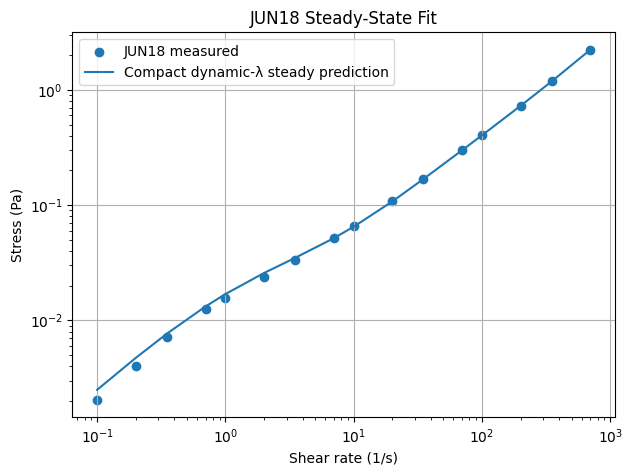

Helton M metrics: {'rmse_Pa': 0.0027164328881981443, 'r2': 0.29219186877876535}
Helton AW metrics: {'rmse_Pa': 0.0020625272672626614, 'r2': 0.8330248520706649}
Helton CY metrics: {'rmse_Pa': 0.0017233304132378703, 'r2': 0.9571041812196117}


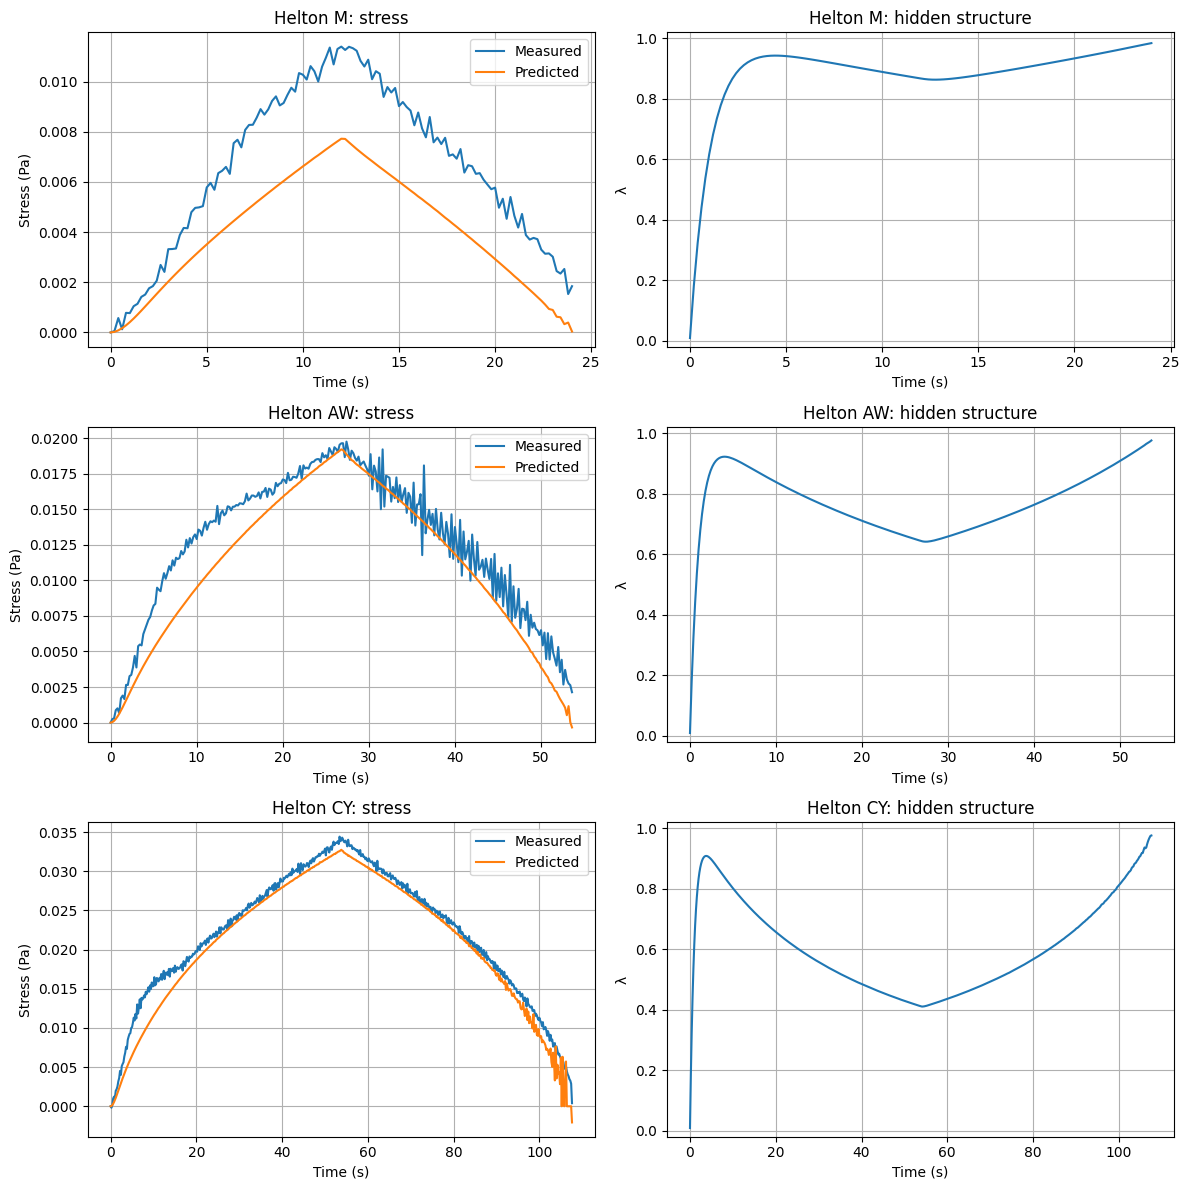

,column,measured_signed_area,predicted_signed_area,measured_absolute_area,predicted_absolute_area
0,M,-0.006453,-0.000490,0.006869,0.000733
1,AW,-0.003546,0.000295,0.010361,0.001520
2,CY,0.003095,0.001392,0.005615,0.001518


In [11]:
# ============================================================
# FIT DIAGNOSTICS
# ============================================================

def jun18_metrics(measured, predicted):
    measured = np.asarray(measured, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    rmse = float(np.sqrt(np.mean((measured - predicted) ** 2)))
    denominator = float(np.sum((measured - measured.mean()) ** 2))
    r2 = (
        float(1 - np.sum((measured - predicted) ** 2) / denominator)
        if denominator > 0
        else np.nan
    )
    return {"rmse_Pa": rmse, "r2": r2}


def jun18_hysteresis_area(shear_rate, stress, number_of_points=250):
    """Integrate the up/down stress gap over log shear rate."""
    shear_rate = np.asarray(shear_rate, dtype=float)
    stress = np.asarray(stress, dtype=float)
    peak = int(np.argmax(np.abs(shear_rate)))

    up_shear = np.abs(shear_rate[:peak + 1])
    up_stress = stress[:peak + 1]
    down_shear = np.abs(shear_rate[peak:])
    down_stress = stress[peak:]

    up_mask = up_shear > 1e-4
    down_mask = down_shear > 1e-4
    up_shear, up_stress = up_shear[up_mask], up_stress[up_mask]
    down_shear, down_stress = down_shear[down_mask], down_stress[down_mask]

    up_order = np.argsort(up_shear)
    down_order = np.argsort(down_shear)
    up_shear, up_stress = up_shear[up_order], up_stress[up_order]
    down_shear, down_stress = down_shear[down_order], down_stress[down_order]

    lower = max(float(up_shear.min()), float(down_shear.min()))
    upper = min(float(up_shear.max()), float(down_shear.max()))
    if not upper > lower:
        return {"signed_area": np.nan, "absolute_area": np.nan}

    grid = np.geomspace(lower, upper, number_of_points)
    up_grid = np.interp(grid, up_shear, up_stress)
    down_grid = np.interp(grid, down_shear, down_stress)
    difference = up_grid - down_grid
    log_grid = np.log(grid)
    return {
        "signed_area": float(np.trapezoid(difference, log_grid)),
        "absolute_area": float(np.trapezoid(np.abs(difference), log_grid)),
    }


steady_shear = jun18_steady["shear_rate"].to_numpy(dtype=float)
steady_measured = jun18_steady["stress"].to_numpy(dtype=float)
steady_predicted = jun18_steady_stress(steady_shear, jun18_parameters)
print("JUN18 steady metrics:", jun18_metrics(steady_measured, steady_predicted))

order = np.argsort(steady_shear)
plt.figure(figsize=(7, 5))
plt.scatter(steady_shear, steady_measured, label="JUN18 measured")
plt.plot(
    steady_shear[order],
    steady_predicted[order],
    label="Compact dynamic-λ steady prediction",
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Shear rate (1/s)")
plt.ylabel("Stress (Pa)")
plt.title("JUN18 Steady-State Fit")
plt.grid(True)
plt.legend()
plt.show()

fig, axes = plt.subplots(
    len(jun18_fit_ramps),
    2,
    figsize=(12, 4 * len(jun18_fit_ramps)),
    squeeze=False,
)

jun18_hysteresis_records = []

for row, (column, ramp) in enumerate(jun18_fit_ramps.items()):
    prediction = jun18_predict_ramp(ramp, jun18_parameters)
    measured = ramp["stress"].to_numpy(dtype=float)
    metrics = jun18_metrics(measured, prediction["stress"])
    print(f"Helton {column} metrics:", metrics)

    measured_area = jun18_hysteresis_area(
        ramp["shear_rate"],
        measured,
    )
    predicted_area = jun18_hysteresis_area(
        prediction["shear_rate"],
        prediction["stress"],
    )
    jun18_hysteresis_records.append({
        "column": column,
        "measured_signed_area": measured_area["signed_area"],
        "predicted_signed_area": predicted_area["signed_area"],
        "measured_absolute_area": measured_area["absolute_area"],
        "predicted_absolute_area": predicted_area["absolute_area"],
    })

    axes[row, 0].plot(ramp["time"], measured, label="Measured")
    axes[row, 0].plot(
        prediction["time"], prediction["stress"], label="Predicted"
    )
    axes[row, 0].set_title(f"Helton {column}: stress")
    axes[row, 0].set_xlabel("Time (s)")
    axes[row, 0].set_ylabel("Stress (Pa)")
    axes[row, 0].grid(True)
    axes[row, 0].legend()

    axes[row, 1].plot(
        prediction["time"], prediction["lambda"], label="Predicted λ"
    )
    axes[row, 1].set_title(f"Helton {column}: hidden structure")
    axes[row, 1].set_xlabel("Time (s)")
    axes[row, 1].set_ylabel("λ")
    axes[row, 1].set_ylim(-0.02, 1.02)
    axes[row, 1].grid(True)

plt.tight_layout()
plt.show()

jun18_hysteresis_table = pd.DataFrame(jun18_hysteresis_records)
display(jun18_hysteresis_table)


Held-out JUN18 5 -> 0.25 metrics: {'rmse_Pa': 0.004367642340940115, 'r2': -1.0837892283932313}


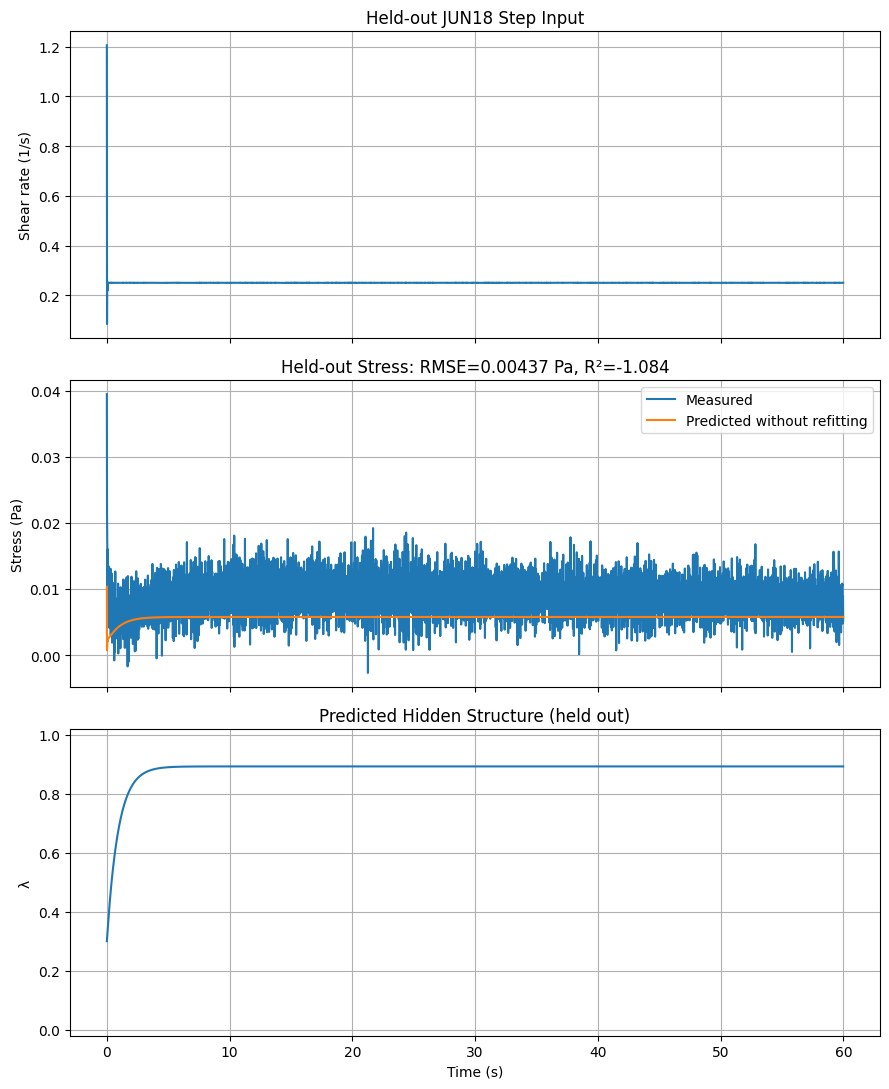

In [12]:
# ============================================================
# HELD-OUT CHECK: JUN18 5 -> 0.25 STEP-DOWN
# No parameter is refitted in this section.
# ============================================================

def jun18_load_step(file_path, start_column):
    raw = pd.read_excel(file_path, sheet_name="Step Up Step Down", header=None)
    start = jun18_excel_col_to_index(start_column)
    title = raw.iloc[0, start]
    data = jun18_clean_series(
        raw=raw,
        time_col=start,
        stress_col=start + 1,
        shear_col=start + 3,
    )
    data.attrs["title"] = title
    return data


jun18_step_5_to_025 = jun18_load_step(
    JUN18_FILE_PATH,
    JUN18_STEP_COLUMN,
)

step_initial_lambda = float(
    jun18_steady_lambda(5.0, jun18_parameters)
)
step_prediction = jun18_predict_ramp(
    jun18_step_5_to_025,
    jun18_parameters,
    initial_lambda=step_initial_lambda,
)

step_measured = jun18_step_5_to_025["stress"].to_numpy(dtype=float)
step_metrics = jun18_metrics(step_measured, step_prediction["stress"])
print("Held-out JUN18 5 -> 0.25 metrics:", step_metrics)

fig, axes = plt.subplots(3, 1, figsize=(9, 11), sharex=True)
axes[0].plot(
    jun18_step_5_to_025["time"],
    jun18_step_5_to_025["shear_rate"],
)
axes[0].set_ylabel("Shear rate (1/s)")
axes[0].set_title("Held-out JUN18 Step Input")
axes[0].grid(True)

axes[1].plot(
    jun18_step_5_to_025["time"],
    step_measured,
    label="Measured",
)
axes[1].plot(
    step_prediction["time"],
    step_prediction["stress"],
    label="Predicted without refitting",
)
axes[1].set_ylabel("Stress (Pa)")
axes[1].set_title(
    f"Held-out Stress: RMSE={step_metrics['rmse_Pa']:.5f} Pa, "
    f"R²={step_metrics['r2']:.3f}"
)
axes[1].grid(True)
axes[1].legend()

axes[2].plot(step_prediction["time"], step_prediction["lambda"])
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("λ")
axes[2].set_ylim(-0.02, 1.02)
axes[2].set_title("Predicted Hidden Structure (held out)")
axes[2].grid(True)

plt.tight_layout()
plt.show()


## How to interpret this extension

- The compact model is an **M2 diagnostic baseline**, not a replacement for the original five-state non-tensorial t-ESSTV model.
- A good Helton fit with poor held-out step prediction means the slow λ-based structural memory is useful, but a faster elastic/stress state is still missing.
- If the held-out result improves relative to the original model, the next step is to reuse this data split, joint loss, log-parameterisation, and multistart fitting with the original five-state equations.
- Do not refit on the held-out step when reporting predictive performance.
- Donor 3 values are used only as numerical starting values; they are not assumed to be the true JUN18 parameters.
